In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import gc
import joblib

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from utils import get_opt, get_loaders
from predictor_definitions import LinearRegression, LogisticRegression, MLPRegressor, MLPClassifier

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import r2_score, roc_auc_score, roc_curve, mean_squared_error

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

In [3]:
layers_to_keep = (0, 1, 23)

# Loading

## Model

In [4]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
# model_name = "HuggingFaceTB/SmolLM2-360M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Data

In [6]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])


## Stored results

In [6]:
# w_rel_norms_L2 = pd.read_csv('w_rel_norms_L2.csv', index_col=0)
# q = 0.3
# w_rel_norms_L2.quantile(q).to_csv('w_rel_norms_L2_q.csv')
# w_rel_norms_L2_q = pd.read_csv('w_rel_norms_L2_q.csv', index_col=0)

In [7]:
importance = pd.read_csv('importance.csv', index_col=0)
w_rel_norms_L2_q = pd.read_csv('w_rel_norms_L2_q.csv', index_col=0)

In [8]:
for i, layer in enumerate(model.model.layers):
    mlp = layer.mlp
    mlp.grad_imp = torch.Tensor(importance.iloc[:, i]).to(dtype=model.dtype, device=DEV)
    mlp.threshold = w_rel_norms_L2_q.iloc[i, 0]

# Collecting data

In [ ]:
def rel_L2_norm(inps_abs, outs_abs):
    return outs_abs.norm(dim=2, keepdim=True) / inps_abs.norm(dim=2, keepdim=True)

def hook_norms(module, inps, outs):
    w_outs_abs = outs.square() * module.grad_imp
    inps_abs = inps[0].abs()
    token_norms = rel_L2_norm(inps_abs, w_outs_abs)
    mask = token_norms >= module.threshold if module.use_threshold else torch.ones_like(token_norms)

    module.inputs.extend(inps[0][0].detach().cpu().float().tolist())
    module.y_norms.extend(token_norms.flatten().detach().cpu().float().tolist())
    module.y_bin.extend(mask.flatten().detach().cpu().float().tolist())

    return outs * mask

In [ ]:
@torch.no_grad()
def collect_data_layer_by_layer(model, dataloader, layers_to_capture, save_dir="mlp_data"):
    use_cache = model.config.use_cache
    model.config.use_cache = False

    os.makedirs(save_dir, exist_ok=True)
    latent_dim = model.model.embed_tokens.embedding_dim

    hooks = []
    for i in layers_to_capture:
        mlp = model.model.layers[i].mlp
        mlp.use_threshold = i not in layers_to_keep

        mlp.inputs = []
        mlp.y_norms = []
        mlp.y_bin = []

        mlp.h = mlp.register_forward_hook(hook_norms)

    # nsamples = 1       # 1 sample = 8192 tokens, there are 2048 parameters in LR
    nsamples = 12        # fix considering train/test ratio ... 1 sample = 8192 tokens, there are (2048+1+1)*32 parameters in NN, (2048+1+1)*32/(8192*0.7) < 12
    
    gc.collect()
    torch.cuda.empty_cache()
    
    for j in range(nsamples):
        # print(j, end=' ')
        model(dataloader[j][0].to(DEV))
    # print()
    
    gc.collect()
    torch.cuda.empty_cache()

    for i in layers_to_capture:
        mlp = model.model.layers[i].mlp
        mlp.h.remove()

        mlp.inputs = torch.Tensor(mlp.inputs)
        mlp.y_norms = torch.Tensor(mlp.y_norms)
        mlp.y_bin = torch.Tensor(mlp.y_bin)

        # Combine into a single DataFrame
        df = pd.DataFrame(mlp.inputs)
        del mlp.inputs
        df['y_norm'] = mlp.y_norms
        df['y_bin'] = mlp.y_bin

        # Save to CSV
        csv_path = os.path.join(save_dir, f"layer_{i}.csv")
        df.to_csv(csv_path)
        print(f"saved data to {csv_path}")

        # Free memory
        del mlp.y_norms, mlp.y_bin, df

    model.config.use_cache = use_cache

In [9]:
# number of mlp params
(2048 + 1) * 32 + (32 + 1)

65601

In [10]:
# amount of collected data
12 * 8192 * 0.7

68812.79999999999

In [11]:
# how many samples are needed
((2048 + 1) * 32 + (32 + 1)) / (8192 * 0.7)

11.439906529017858

In [ ]:
layers_subset_size = 4
for i in range(0, 24, layers_subset_size):
    collect_data_layer_by_layer(model, wiki_dataloader, range(i, i+layers_subset_size))

# Predictors

## Utils

### Data loading functions

In [16]:
def load_data(csv_path, verbose=True):
    df = pd.read_csv(csv_path, index_col=0)
    if verbose: print(f"Data shape: {df.shape}")
    # Separate features and targets
    X = df.drop(['y_norm', 'y_bin'], axis=1)
    y_reg = df['y_norm'].values  # Regression target
    y_cls = df['y_bin'].values   # Classification target
    return X, y_reg, y_cls


def split_data(X, y_reg, y_cls, val_size=0.15, test_size=0.15, verbose=True):
    X_temp, X_test, y_reg_temp, y_reg_test, y_cls_temp, y_cls_test = train_test_split(
        X, y_reg, y_cls, test_size=test_size, random_state=42
    )
    val_adjusted_size = val_size / (1 - test_size)
    X_train, X_val, y_reg_train, y_reg_val, y_cls_train, y_cls_val = train_test_split(
        X_temp, y_reg_temp, y_cls_temp, test_size=val_adjusted_size, random_state=42
    )
    # Scale features
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    # Scale outputs
    scaler_y = MinMaxScaler()
    y_reg_train = scaler_y.fit_transform(y_reg_train.reshape(-1, 1))
    y_reg_val = scaler_y.transform(y_reg_val.reshape(-1, 1))
    y_reg_test = scaler_y.transform(y_reg_test.reshape(-1, 1))
    
    if verbose:
        print(f"Train set: {X_train.shape[0]} samples")
        print(f"Validation set: {X_val.shape[0]} samples")
        print(f"Test set: {X_test.shape[0]} samples")

    # Convert to PyTorch tensors
    X_train_tensor = torch.FloatTensor(X_train)
    X_val_tensor = torch.FloatTensor(X_val)
    X_test_tensor = torch.FloatTensor(X_test)

    y_reg_train_tensor = torch.FloatTensor(y_reg_train.reshape(-1, 1))
    y_reg_val_tensor = torch.FloatTensor(y_reg_val.reshape(-1, 1))
    y_reg_test_tensor = torch.FloatTensor(y_reg_test.reshape(-1, 1))

    y_cls_train_tensor = torch.FloatTensor(y_cls_train.reshape(-1, 1))
    y_cls_val_tensor = torch.FloatTensor(y_cls_val.reshape(-1, 1))
    y_cls_test_tensor = torch.FloatTensor(y_cls_test.reshape(-1, 1))

    return {
        'X_train': X_train_tensor, 'X_val': X_val_tensor, 'X_test': X_test_tensor,
        'y_reg_train': y_reg_train_tensor, 'y_reg_val': y_reg_val_tensor, 'y_reg_test': y_reg_test_tensor,
        'y_cls_train': y_cls_train_tensor, 'y_cls_val': y_cls_val_tensor, 'y_cls_test': y_cls_test_tensor
    }

### Eval functions

In [17]:
def evaluate_regression(model, data_dict, verbose=True):
    with torch.no_grad():
        y_pred = model.predict(data_dict['X_test'])
        y_true = data_dict['y_reg_test'].cpu().numpy()
        if np.isnan(y_pred).any():
            return {'R2': np.nan, 'MSE': np.nan}
        r2 = r2_score(y_true, y_pred)
        mse = np.mean((y_true - y_pred) ** 2)
        if verbose:
            print("\nLinear Regression Model Evaluation:")
            print(f"R² Score: {r2:.4f}")
            print(f"MSE: {mse:.4f}")

            # Plot predictions vs actual
            plt.figure(figsize=(10, 6))
            plt.scatter(y_true, y_pred, alpha=0.5)
            plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')
            plt.xlabel('Actual Values')
            plt.ylabel('Predicted Values')
            plt.title('Linear Regression: Predicted vs Actual')
            plt.show()
        return {'R2': r2, 'MSE': mse}

def evaluate_classification(model, data_dict, verbose=True):
    with torch.no_grad():
        y_pred_proba = model.predict(data_dict['X_test'])
        y_true = data_dict['y_cls_test'].cpu().numpy()
        
        auc = roc_auc_score(y_true, y_pred_proba) if len(np.unique(y_true)) > 1 else np.nan
        y_pred_binary = (y_pred_proba > 0.5).astype(int)
        accuracy = np.mean(y_pred_binary == y_true)

        if verbose:
            print("\nLogistic Regression Model Evaluation:")
            print(f"AUC Score: {auc:.4f}")
            print(f"Accuracy: {accuracy:.4f}")

            fpr, tpr, _ = roc_curve(y_true, y_pred_proba)

            plt.figure(figsize=(10, 6))
            plt.plot(fpr, tpr, label=f'AUC = {auc:.4f}')
            plt.plot([0, 1], [0, 1], 'k--')
            plt.xlabel('False Positive Rate')
            plt.ylabel('True Positive Rate')
            plt.title('ROC Curve - Logistic Regression')
            plt.legend()
            plt.show()

        return {'AUC': auc, 'Accuracy': accuracy}

In [14]:
# i = 4
# csv_path = f"mlp_data/layer_{i}.csv"
# X, y_reg, y_cls = load_data(csv_path, verbose=False)
# data_dict = split_data(X, y_reg, y_cls, verbose=False)

### Output format

In [18]:
def format_num(val, chars=5):
    s = f"{val}"
    return s[:chars].rjust(chars) if len(s) > chars else s.rjust(chars)

def color_r2(x):
    if float(x) < 0:
        return f"\033[91m{x}\033[0m"  # Red
    elif float(x) < 0.5:
        return f"\033[93m{x}\033[0m"  # Yellow
    else:
        return x

def color_auc(x):
    if float(x) < 0.5:
        return f"\033[91m{x}\033[0m"  # Red
    if float(x) < 0.75:
        return f"\033[93m{x}\033[0m"  # Yellow
    else:
        return x

## Train prediction models for each layer

In [19]:
def layer_predictors(regressor, classifier, label='',
                     reg_lrs=(1e-2, 1e-3, 1e-4), cls_lrs=(1e-1, 1e-2, 1e-3)):
    results = pd.DataFrame(columns=['lr', 'R2', 'AUC'])
    
    for i in range(len(model.model.layers)):
        if i in layers_to_keep: 
            continue
        print(f"Layer {i}:")
        
        # Load layer data
        csv_path = f"mlp_data/layer_{i}.csv"
        X, y_reg, y_cls = load_data(csv_path, verbose=False)
        data_dict = split_data(X, y_reg, y_cls, verbose=False)

        best_auc = float('-inf')
        best_r2 = float('-inf')
        best_reg_lr, best_cls_lr = None, None
        best_reg_model, best_cls_model = None, None

        # Try different learning rates for regression
        for lr in reg_lrs:
            print_line = f"learning_rate={lr:<6} | "
            reg_model = regressor(lr)
            reg_model.fit(data_dict['X_train'], data_dict['y_reg_train'],
                          data_dict['X_val'], data_dict['y_reg_val'])
            if reg_model:
                reg_metrics = evaluate_regression(reg_model, data_dict, verbose=False)
                r2 = format_num(reg_metrics['R2'])
                print_line += f"R2={color_r2(r2)}"
                if reg_metrics['R2'] > best_r2:
                    best_r2 = reg_metrics['R2']
                    best_reg_model = reg_model
                    best_reg_lr = lr
            print(print_line)

        # Try different learning rates for classification (only if more than one class present)
        if len(np.unique(data_dict['y_cls_train'])) > 1:
            for lr in cls_lrs:
                print_line = f"learning_rate={lr:<6} | "
                cls_model = classifier(lr)
                cls_model.fit(data_dict['X_train'], data_dict['y_cls_train'],
                              data_dict['X_val'], data_dict['y_cls_val'])
                if cls_model:
                    cls_metrics = evaluate_classification(cls_model, data_dict, verbose=False)
                    auc = format_num(cls_metrics['AUC'])
                    print_line += f"AUC={color_auc(auc)}"
                    if cls_metrics['AUC'] > best_auc:
                        best_auc = cls_metrics['AUC']
                        best_cls_model = cls_model
                        best_cls_lr = lr
                print(print_line)

        # Save best models
        r2, auc = 0, 0.5
        if best_reg_model is not None:
            r2 = best_r2
            save_path = f"predictors/reg_model{label}_layer{i}.pkl"
            os.makedirs(os.path.dirname(save_path), exist_ok=True)
            joblib.dump(best_reg_model, save_path)
        if best_cls_model is not None:
            auc = best_auc
            save_path = f"predictors/cls_model{label}_layer{i}.pkl"
            os.makedirs(os.path.dirname(save_path), exist_ok=True)
            joblib.dump(best_cls_model, save_path)

        results.loc[i] = [f"{best_reg_lr}/{best_cls_lr}", r2, auc]
    
    return results


In [22]:
results = layer_predictors(regressor=LinearRegression, classifier=LogisticRegression, label='',
                           reg_lrs=(1e-1, 1e-2, 1e-3, 1e-4), cls_lrs=(100, 10, 1, 1e-1))

Layer 2:
learning_rate=0.1    | R2=-3.79
learning_rate=0.01   | R2=-2.05
learning_rate=0.001  | R2=-1.38
learning_rate=0.0001 | R2=-9.15
learning_rate=100    | AUC=0.878
learning_rate=10     | AUC=0.889
learning_rate=1      | AUC=0.881
learning_rate=0.1    | AUC=0.868
Layer 3:
learning_rate=0.1    | R2=0.097
learning_rate=0.01   | R2=0.288
learning_rate=0.001  | R2=0.458
learning_rate=0.0001 | R2=-0.02
learning_rate=100    | AUC=0.897
learning_rate=10     | AUC=0.902
learning_rate=1      | AUC=0.891
learning_rate=0.1    | AUC=0.866
Layer 4:
learning_rate=0.1    | R2=0.471
learning_rate=0.01   | R2=0.568
learning_rate=0.001  | R2=0.637
learning_rate=0.0001 | R2=0.292
learning_rate=100    | AUC=0.883
learning_rate=10     | AUC=0.889
learning_rate=1      | AUC=0.894
learning_rate=0.1    | AUC=0.868
Layer 5:
learning_rate=0.1    | R2=0.563
learning_rate=0.01   | R2=0.576
learning_rate=0.001  | R2=0.583
learning_rate=0.0001 | R2=0.553
learning_rate=100    | AUC=0.821
learning_rate=10     | 

In [23]:
results_mlp = layer_predictors(
    regressor=MLPRegressor, classifier=MLPClassifier, label='_mlp',
    reg_lrs=(1e-2, 1e-3, 1e-4, 1e-5), cls_lrs=(100, 10, 1, 1e-1))

Layer 2:
learning_rate=0.01   | R2=-161.
learning_rate=0.001  | R2=-0.79
learning_rate=0.0001 | R2=-1.64
learning_rate=1e-05  | R2=-1.82
learning_rate=100    | AUC=0.903
learning_rate=10     | AUC=0.904
learning_rate=1      | AUC=0.894
learning_rate=0.1    | AUC=0.862
Layer 3:
learning_rate=0.01   | R2=-66.4
learning_rate=0.001  | R2=0.340
learning_rate=0.0001 | R2=-2.26
learning_rate=1e-05  | R2=-2.33
learning_rate=100    | AUC=0.911
learning_rate=10     | AUC=0.916
learning_rate=1      | AUC=0.906
learning_rate=0.1    | AUC=0.865
Layer 4:
learning_rate=0.01   | R2=-8.20
learning_rate=0.001  | R2=0.713
learning_rate=0.0001 | R2=-1.61
learning_rate=1e-05  | R2=-1.65
learning_rate=100    | AUC=0.895
learning_rate=10     | AUC=0.913
learning_rate=1      | AUC=0.906
learning_rate=0.1    | AUC=0.872
Layer 5:
learning_rate=0.01   | R2=-0.32
learning_rate=0.001  | R2=0.553
learning_rate=0.0001 | R2=0.369
learning_rate=1e-05  | R2=-1.89
learning_rate=100    | AUC=0.853
learning_rate=10     | 

# Results

In [24]:
prediction_results = pd.merge(results, results_mlp, right_index=True, left_index=True, suffixes=('', '_mlp'))
prediction_results.to_csv('prediction_results.csv')
prediction_results

,lr,R2,AUC,lr_mlp,R2_mlp,AUC_mlp
2,0.001/10,-1.386678,0.889773,0.001/10,-0.799797,0.904193
3,0.001/10,0.458074,0.902274,0.001/10,0.340212,0.916440
4,0.001/1,0.637634,0.894721,0.001/10,0.713998,0.913361
5,0.001/10,0.583195,0.828070,0.001/100,0.553325,0.853392
6,0.01/10,0.174011,0.817319,0.001/100,-0.000221,0.843957
7,0.1/100,0.792666,0.860853,0.001/10,0.685391,0.869581
8,0.01/100,0.782333,0.806708,0.001/100,0.797149,0.849841
9,0.01/10,0.739174,0.868227,0.001/10,0.747176,0.876286
10,0.001/100,0.617692,0.802305,0.001/10,0.747116,0.818436
11,0.01/100,0.583066,0.812648,0.001/10,0.766104,0.824588


## Visualization

In [25]:
all_results = pd.read_csv('prediction_results.csv', index_col=0)

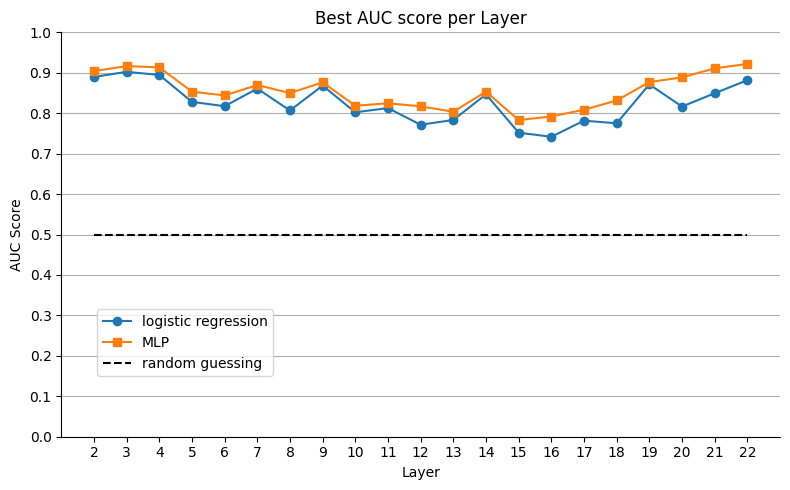

In [26]:
layers = list(all_results.index)

plt.figure(figsize=(8, 5))

plt.plot(layers, all_results['AUC'], marker='o', label='logistic regression')
plt.plot(layers, all_results['AUC_mlp'], marker='s', label='MLP')
plt.plot([min(layers), max(layers)], [0.5, 0.5], linestyle='--', label='random guessing', color='black')

plt.title('Best AUC score per Layer')
plt.xlabel('Layer')
plt.ylabel('AUC Score')
plt.ylim((0, 1))
plt.grid(axis='y')
plt.xticks(layers)
plt.yticks([x/10 for x in range(11)])
plt.legend(loc=(0.05, 0.15))
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

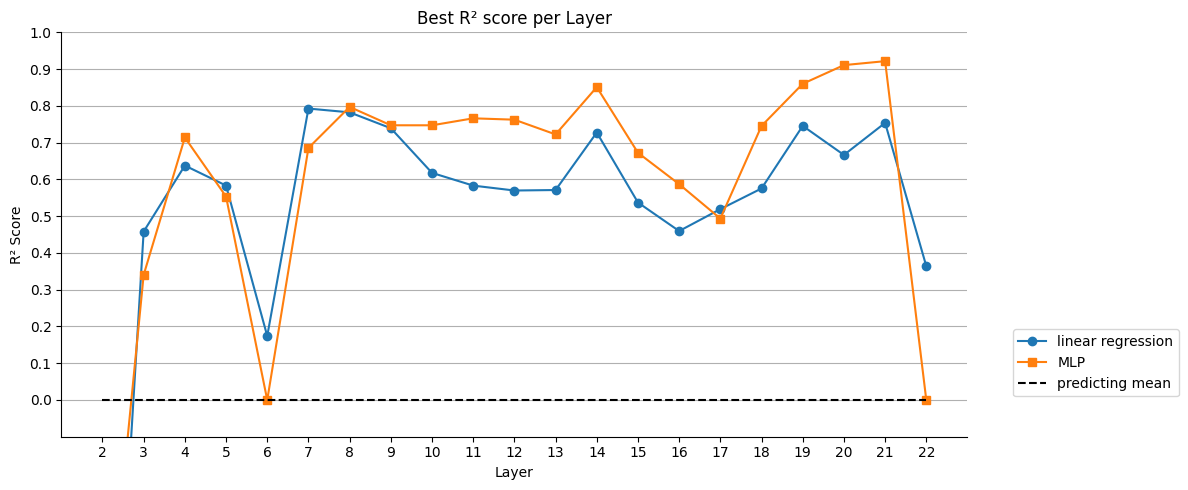

In [27]:
layers = list(all_results.index)

plt.figure(figsize=(12, 5))

plt.plot(layers, all_results['R2'], marker='o', label='linear regression')
plt.plot(layers, all_results['R2_mlp'], marker='s', label='MLP')
plt.plot([min(layers), max(layers)], [0, 0], linestyle='--', label='predicting mean', color='black')

plt.title('Best R² score per Layer')
plt.xlabel('Layer')
plt.ylabel('R² Score')
plt.ylim((-0.1, 1))
plt.grid(axis='y')
plt.xticks(layers)
plt.yticks([x/10 for x in range(11)])
plt.legend(loc=(1.05, 0.1))
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

# Old results

In [39]:
# results_less_data = pd.read_csv('prediction_results.csv', index_col=0)
# results_more_data = pd.merge(results, results_mlp, right_index=True, left_index=True, suffixes=('', '_mlp'))
# all_results = pd.merge(results_less_data, results_more_data, right_index=True, left_index=True, suffixes=('', '_more_data'))
# all_results.to_csv('all_prediction_results.csv')

In [40]:
# old
all_results = pd.read_csv('all_prediction_results.csv', index_col=0)
all_results

,lr,R2,AUC,lr_mlp,R2_mlp,AUC_mlp,lr_more_data,R2_more_data,AUC_more_data,lr_mlp_more_data,R2_mlp_more_data,AUC_mlp_more_data
2,0.01/10,0.727577,0.875367,0.001/10,0.673432,0.876903,0.001/10,0.750087,0.887116,0.001/10,0.357565,0.899636
3,0.001/1,0.798449,0.896149,0.001/10,0.617070,0.898460,0.01/10,0.814525,0.905433,0.01/10,0.731705,0.917112
4,0.01/1,0.743315,0.860620,0.001/1,0.724954,0.862641,0.001/10,0.796629,0.868411,0.01/10,0.699956,0.900487
5,0.001/100,0.574372,0.793559,0.001/10,0.545961,0.808120,0.001/10,0.649964,0.808350,0.01/10,0.657667,0.831842
6,0.01/1,0.741896,0.772738,0.001/0.1,0.722256,0.755812,0.001/10,0.519075,0.770287,0.001/10,0.104174,0.794136
7,0.01/10,0.905042,0.797700,0.001/1,0.649593,0.785025,0.01/10,0.721500,0.798857,0.001/10,0.054159,0.819140
8,0.001/1,0.737515,0.775009,0.001/100,0.739845,0.783110,0.1/100,0.792633,0.838268,0.01/10,0.788256,0.853222
9,0.1/10,0.545423,0.786547,0.001/1,0.602234,0.784671,0.001/10,0.674924,0.797205,0.001/100,0.755318,0.825430
10,0.01/10,0.474387,0.778343,0.001/1,0.495068,0.766428,0.01/1,0.528353,0.756460,0.01/100,0.496438,0.764883
11,0.1/1,0.374304,0.740374,0.001/10,0.483748,0.744497,0.01/1,0.473471,0.719698,0.01/10,0.672616,0.706224


### Classification results

In [41]:
all_results[filter(lambda x: 'AUC' in x, all_results.columns)]

,AUC,AUC_mlp,AUC_more_data,AUC_mlp_more_data
2,0.875367,0.876903,0.887116,0.899636
3,0.896149,0.898460,0.905433,0.917112
4,0.860620,0.862641,0.868411,0.900487
5,0.793559,0.808120,0.808350,0.831842
6,0.772738,0.755812,0.770287,0.794136
7,0.797700,0.785025,0.798857,0.819140
8,0.775009,0.783110,0.838268,0.853222
9,0.786547,0.784671,0.797205,0.825430
10,0.778343,0.766428,0.756460,0.764883
11,0.740374,0.744497,0.719698,0.706224


## Visualization

### Classification models

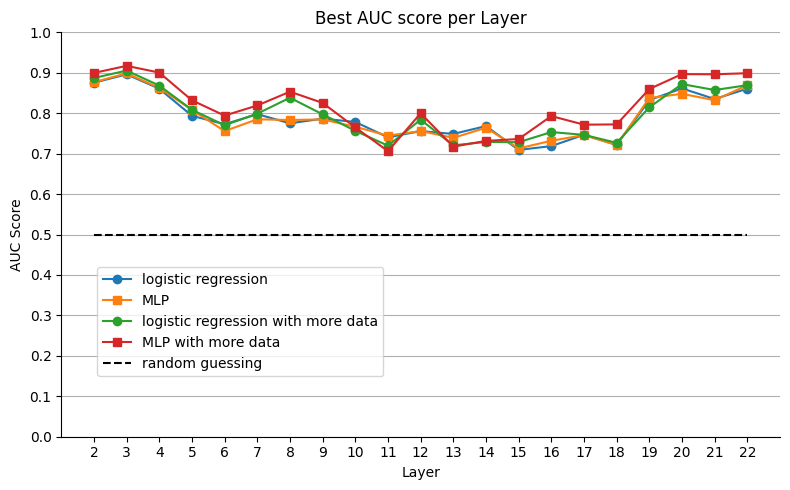

In [88]:
layers = list(all_results.index)

plt.figure(figsize=(8, 5))

plt.plot(layers, all_results['AUC'], marker='o', label='logistic regression')
plt.plot(layers, all_results['AUC_mlp'], marker='s', label='MLP')
plt.plot(layers, all_results['AUC_more_data'], marker='o', label='logistic regression with more data')
plt.plot(layers, all_results['AUC_mlp_more_data'], marker='s', label='MLP with more data')
plt.plot([min(layers), max(layers)], [0.5, 0.5], linestyle='--', label='random guessing', color='black')

plt.title('Best AUC score per Layer')
plt.xlabel('Layer')
plt.ylabel('AUC Score')
plt.ylim((0, 1))
plt.grid(axis='y')
plt.xticks(layers)
plt.yticks([x/10 for x in range(11)])
plt.legend(loc=(0.05, 0.15))
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

### Regression models

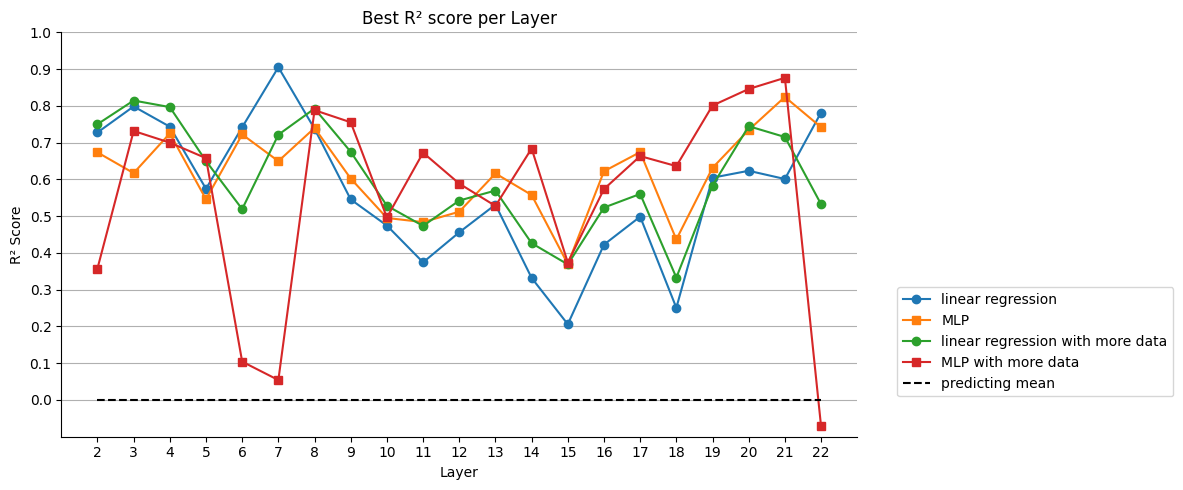

In [89]:
layers = list(all_results.index)

plt.figure(figsize=(12, 5))

plt.plot(layers, all_results['R2'], marker='o', label='linear regression')
plt.plot(layers, all_results['R2_mlp'], marker='s', label='MLP')
plt.plot(layers, all_results['R2_more_data'], marker='o', label='linear regression with more data')
plt.plot(layers, all_results['R2_mlp_more_data'], marker='s', label='MLP with more data')
plt.plot([min(layers), max(layers)], [0, 0], linestyle='--', label='predicting mean', color='black')

plt.title('Best R² score per Layer')
plt.xlabel('Layer')
plt.ylabel('R² Score')
plt.ylim((-0.1, 1))
plt.grid(axis='y')
plt.xticks(layers)
plt.yticks([x/10 for x in range(11)])
plt.legend(loc=(1.05, 0.1))
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

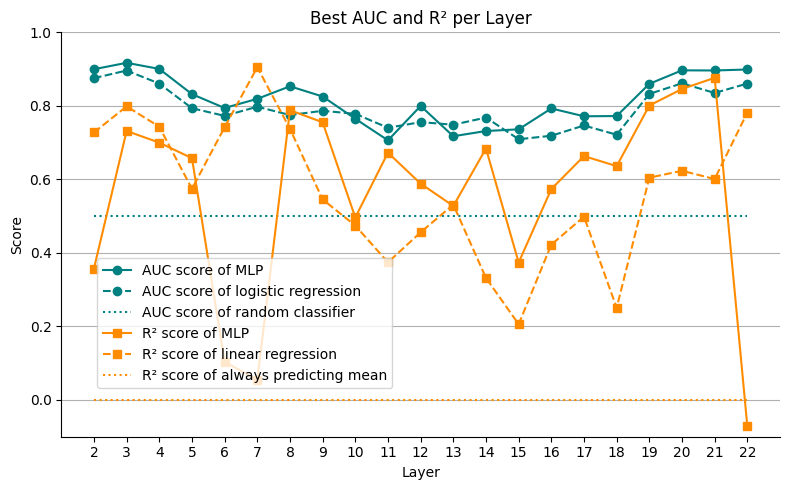

In [90]:
# porovnanie: regresia trenovana na mensich datach vs. MLP na vacsich datach
layers = list(results_less_data.index)
auc_values = all_results['AUC']
r2_values = all_results['R2']
mlp_auc_values = all_results['AUC_mlp_more_data']
mlp_r2_values = all_results['R2_mlp_more_data']

plt.figure(figsize=(8, 5))

plt.plot(layers, mlp_auc_values, marker='o', linestyle='-', label='AUC score of MLP', color='teal')
plt.plot(layers, auc_values, marker='o', linestyle='--', label='AUC score of logistic regression', color='teal')
plt.plot([min(layers), max(layers)], [0.5, 0.5], linestyle=':', label='AUC score of random classifier', color='teal')

plt.plot(layers, mlp_r2_values, marker='s', linestyle='-', label='R² score of MLP', color='darkorange')
plt.plot(layers, r2_values, marker='s', linestyle='--', label='R² score of linear regression', color='darkorange')
plt.plot([min(layers), max(layers)], [0, 0], linestyle=':', label='R² score of always predicting mean', color='darkorange')

plt.title('Best AUC and R² per Layer')
plt.xlabel('Layer')
plt.ylabel('Score')
plt.ylim((-0.1, 1))
plt.grid(axis='y')
plt.xticks(layers)
plt.legend(loc=(0.05, 0.12))
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

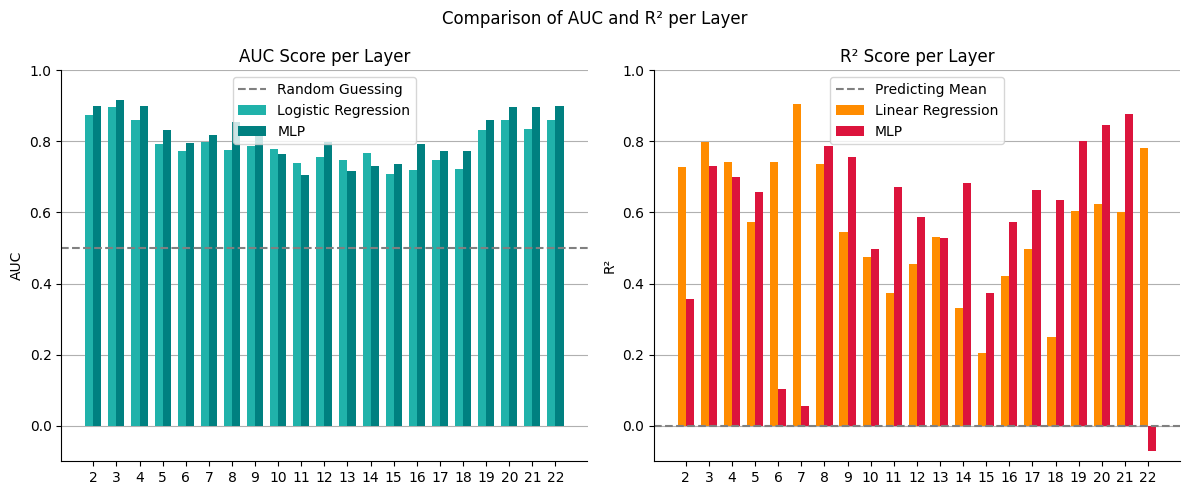

In [69]:
layers = list(all_results.index)
auc_values = all_results['AUC']
r2_values = all_results['R2']
mlp_auc_values = all_results['AUC_mlp_more_data']
mlp_r2_values = all_results['R2_mlp_more_data']

x = np.arange(len(layers))
width = 0.35

fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharex=True)

# AUC subplot
axs[0].axhline(0.5, linestyle='--', color='gray', label='Random Guessing')
axs[0].bar(x - width/2, auc_values, width, label='Logistic Regression', color='lightseagreen')
axs[0].bar(x + width/2, mlp_auc_values, width, label='MLP', color='teal')
axs[0].set_title('AUC Score per Layer')
axs[0].set_ylabel('AUC')
axs[0].set_ylim((-0.1, 1))
axs[0].set_xticks(x)
axs[0].set_xticklabels(layers)
axs[0].legend()
axs[0].grid(axis='y')
axs[0].set_axisbelow(True)
axs[0].spines['right'].set_visible(False)
axs[0].spines['top'].set_visible(False)

# R² subplot
axs[1].axhline(0, linestyle='--', color='gray', label='Predicting Mean')
axs[1].bar(x - width/2, r2_values, width, label='Linear Regression', color='darkorange')
axs[1].bar(x + width/2, mlp_r2_values, width, label='MLP', color='crimson')
axs[1].set_title('R² Score per Layer')
axs[1].set_ylabel('R²')
axs[1].set_ylim((-0.1, 1))
axs[1].set_xticks(x)
axs[1].set_xticklabels(layers)
axs[1].legend()
axs[1].grid(axis='y')
axs[1].set_axisbelow(True)
axs[1].spines['right'].set_visible(False)
axs[1].spines['top'].set_visible(False)

fig.suptitle('Comparison of AUC and R² per Layer')
plt.tight_layout()
plt.show()


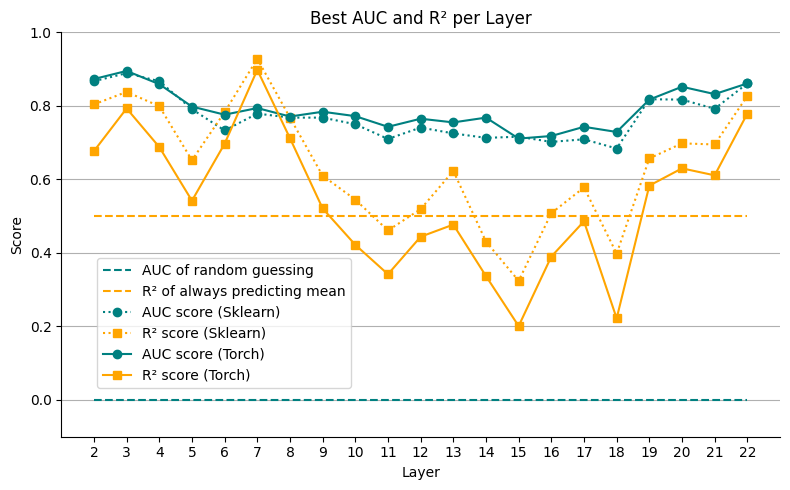

In [17]:
# porovnanie sklearn implementacie a torch
layers = list(best_scores_sklearn.keys())
auc_values = [score[0] for score in best_scores_sklearn.values()]
r2_values = [score[1] for score in best_scores_sklearn.values()]

plt.figure(figsize=(8, 5))
plt.plot([min(layers), max(layers)], [0, 0], linestyle='--', label='AUC of random guessing', color='teal')
plt.plot([min(layers), max(layers)], [0.5, 0.5], linestyle='--', label='R² of always predicting mean', color='orange')
plt.plot(layers, auc_values, marker='o', linestyle=':', label='AUC score (Sklearn)', color='teal')
plt.plot(layers, r2_values, marker='s', linestyle=':', label='R² score (Sklearn)', color='orange')

# vysledky s mojimi Torch class
layers = list(best_score_torch.keys())
auc_values = [score[0] for score in best_score_torch.values()]
r2_values = [score[1] for score in best_score_torch.values()]

plt.plot(layers, auc_values, marker='o', linestyle='-', label='AUC score (Torch)', color='teal')
plt.plot(layers, r2_values, marker='s', linestyle='-', label='R² score (Torch)', color='orange')

plt.title('Best AUC and R² per Layer')
plt.xlabel('Layer')
plt.ylabel('Score')
plt.ylim((-0.1, 1))
plt.grid(axis='y')
plt.xticks(layers)
plt.legend(loc=(0.05, 0.12))
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()